In [4]:
!pip install pandas numpy matplotlib seaborn
!pip install scikit-learn nltk wordcloud

Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels
Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels


In [7]:
%pip install wordcloud

Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from wordcloud import WordCloud

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.decomposition import LatentDirichletAllocation

import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')

print("All libraries imported successfully!")

All libraries imported successfully!


[nltk_data] Downloading package stopwords to
[nltk_data]     /home/3890e073-1f4c-4b2e-bd66-
[nltk_data]     25a2c6519592/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [3]:
# Load the dataset

import pandas as pd

df = pd.read_csv("synthetic_medical_aid_reviews_500.csv")

print(df.head())

print("Dataset shape:", df.shape)

print(df["Sentiment"].value_counts())

  Review_ID Review_Date                                    Provider  \
0  SYN-0060  2025-03-27  Generic South African Medical Aid Provider   
1  SYN-0324  2024-06-10  Generic South African Medical Aid Provider   
2  SYN-0034  2023-10-15  Generic South African Medical Aid Provider   
3  SYN-0316  2024-04-07  Generic South African Medical Aid Provider   
4  SYN-0117  2025-07-11  Generic South African Medical Aid Provider   

                Review_Title  \
0       Medical aid benefits   
1  Customer service feedback   
2  Customer service feedback   
3  Customer service feedback   
4       Medical aid benefits   

                                     Customer_Review  Rating Sentiment  \
0  I am a member and can say that i was charged a...       1  Negative   
1  After contacting the medical aid, i am satisfi...       5  Positive   
2  I would like to share that i was charged an un...       2  Negative   
3  I would like to share that the membership proc...       3   Neutral   
4  I would

In [4]:
# Display dataset information

df.info()

# Display the number of rows and columns

print(df.shape)

# Display column names

print(df.columns)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Review_ID          500 non-null    object
 1   Review_Date        500 non-null    object
 2   Provider           500 non-null    object
 3   Review_Title       500 non-null    object
 4   Customer_Review    500 non-null    object
 5   Rating             500 non-null    int64 
 6   Sentiment          500 non-null    object
 7   Sentiment_Source   500 non-null    object
 8   Feedback_Category  500 non-null    object
 9   Data_Type          500 non-null    object
dtypes: int64(1), object(9)
memory usage: 39.2+ KB
(500, 10)
Index(['Review_ID', 'Review_Date', 'Provider', 'Review_Title',
       'Customer_Review', 'Rating', 'Sentiment', 'Sentiment_Source',
       'Feedback_Category', 'Data_Type'],
      dtype='object')


Data Cleaning and Preparation

In [5]:
# Remove duplicate records

df = df.drop_duplicates()

# Remove records without customer reviews

df = df.dropna(subset=["Customer_Review"])

# Convert reviews into strings

df["Customer_Review"] = df["Customer_Review"].astype(str)

# Create a text-cleaning function

def clean_text(text):

    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove special characters and numbers
    text = re.sub(r"[^a-zA-Z\s]", "", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text)

    return text.strip()


# Apply cleaning

df["Cleaned_Review"] = df["Customer_Review"].apply(clean_text)

# Display cleaned reviews

df[["Customer_Review", "Cleaned_Review"]].head()

,Customer_Review,Cleaned_Review
0,I am a member and can say that i was charged a...,i am a member and can say that i was charged a...
1,"After contacting the medical aid, i am satisfi...",after contacting the medical aid i am satisfie...
2,I would like to share that i was charged an un...,i would like to share that i was charged an un...
3,I would like to share that the membership proc...,i would like to share that the membership proc...
4,I would like to share that it was difficult to...,i would like to share that it was difficult to...


Check missing values

In [6]:
print(df.isnull().sum())

Review_ID            0
Review_Date          0
Provider             0
Review_Title         0
Customer_Review      0
Rating               0
Sentiment            0
Sentiment_Source     0
Feedback_Category    0
Data_Type            0
Cleaned_Review       0
dtype: int64


Check duplicates

In [7]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


Exploratory Data Analysis (EDA)

Examine customer ratings

In [8]:
print(df["Rating"].value_counts().sort_index())

Rating
1     99
2     81
3    140
4     79
5    101
Name: count, dtype: int64


Visualise the ratings

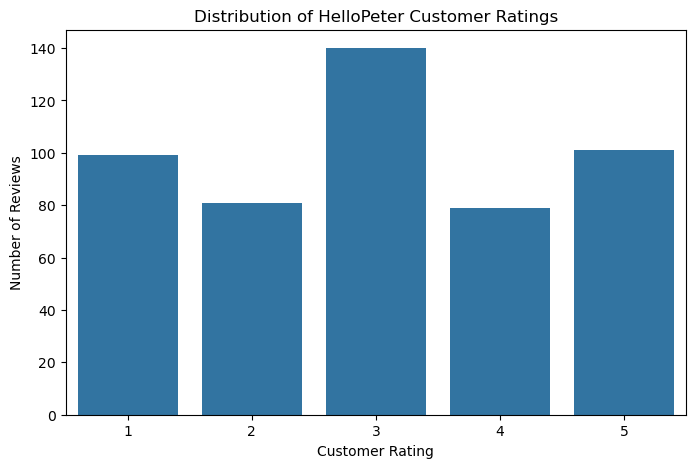

In [9]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x="Rating")

plt.title("Distribution of HelloPeter Customer Ratings")
plt.xlabel("Customer Rating")
plt.ylabel("Number of Reviews")

plt.show()

The bar chart illustrates how customer ratings are distributed across the dataset.

A high concentration of lower ratings may indicate customer dissatisfaction, while higher ratings may indicate positive customer experiences.


Analyse review lengths

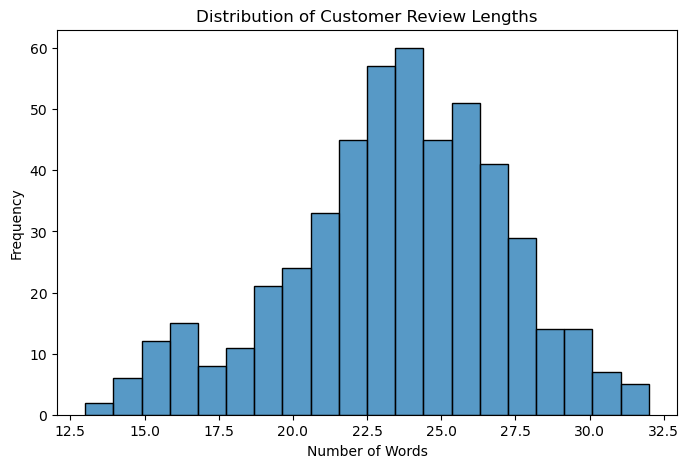

In [10]:
df["Review_Length"] = df["Cleaned_Review"].apply(
    lambda x: len(x.split())
)

plt.figure(figsize=(8,5))

sns.histplot(df["Review_Length"], bins=20)

plt.title("Distribution of Customer Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

This graph illustrates the length of customer reviews. Longer reviews may provide more detailed explanations of customer experiences, while shorter reviews may contain brief complaints or feedback.

Identify frequently used words

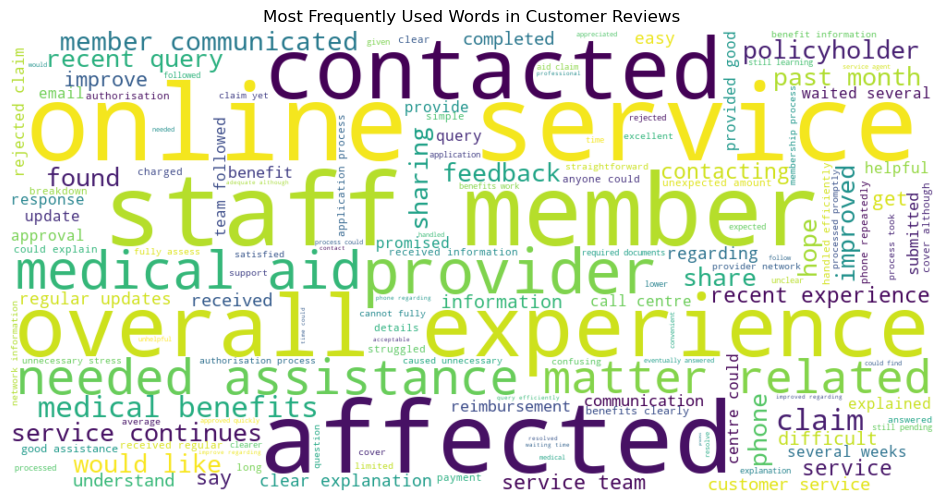

In [11]:
stop_words = set(stopwords.words("english"))

all_words = " ".join(df["Cleaned_Review"])

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    stopwords=stop_words
).generate(all_words)

plt.figure(figsize=(12,6))

plt.imshow(wordcloud, interpolation="bilinear")

plt.axis("off")

plt.title("Most Frequently Used Words in Customer Reviews")

plt.show()

The word cloud provides a visual representation of commonly used words in customer reviews.

Words appearing more frequently may indicate recurring customer experiences or concerns. However, word frequency alone does not establish whether a topic is positive or negative.

Create sentiment categories

In [12]:
def classify_sentiment(rating):

    if rating in [1, 2]:
        return "Negative"

    elif rating == 3:
        return "Neutral"

    elif rating in [4, 5]:
        return "Positive"

    else:
        return None


df["Sentiment"] = df["Rating"].apply(classify_sentiment)

# Remove reviews without valid sentiment labels

df = df.dropna(subset=["Sentiment"])

print(df["Sentiment"].value_counts())


Sentiment
Negative    180
Positive    180
Neutral     140
Name: count, dtype: int64


Feature selection using TF-IDF

In [13]:
X = df["Cleaned_Review"]

y = df["Sentiment"]

# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [14]:
model_pipeline = Pipeline([

    ("tfidf", TfidfVectorizer(
        stop_words="english",
        max_features=5000,
        ngram_range=(1,2)
    )),

    ("feature_selection", SelectKBest(
        score_func=chi2,
        k=1000
    )),

    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))

])

In [ ]:
Train the machine learning model

In [16]:
# Train the model

model_pipeline.fit(X_train, y_train)

print("Model training completed successfully.")

Model training completed successfully.


/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/sklearn/feature_selection/_univariate_selection.py:782: UserWarning: k=1000 is greater than n_features=577. All the features will be returned.
  warnings.warn(



The model learns patterns from the training dataset and uses these patterns to distinguish between positive, neutral and negative customer reviews.

The model has been trained using TF-IDF features and Chi-square feature selection.

Evaluate the model

In [17]:
# Generate predictions

y_pred = model_pipeline.predict(X_test)

# Calculate accuracy

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

# Display classification report

print(classification_report(y_test, y_pred))

Model Accuracy: 1.0
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        36
     Neutral       1.00      1.00      1.00        28
    Positive       1.00      1.00      1.00        36

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100




Confusion matrix

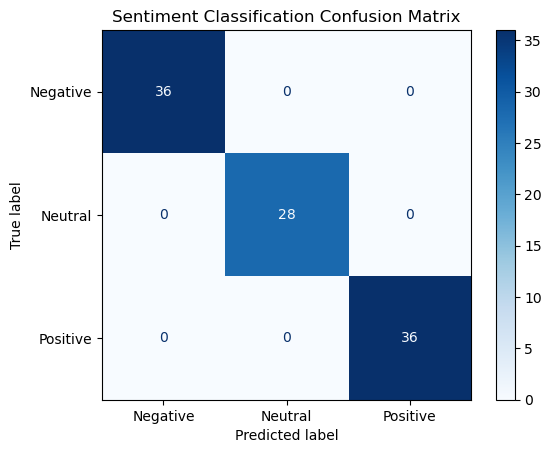

In [18]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Negative", "Neutral", "Positive"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

disp.plot(cmap="Blues")

plt.title("Sentiment Classification Confusion Matrix")

plt.show()

Identify the main areas of customer concern using LDA

In [19]:
# Convert reviews into word frequency vectors

vectorizer = CountVectorizer(
    stop_words="english",
    max_df=0.95,
    min_df=2,
    max_features=5000
)

review_matrix = vectorizer.fit_transform(
    df["Cleaned_Review"]
)

# Create LDA model

lda_model = LatentDirichletAllocation(
    n_components=5,
    random_state=42,
    max_iter=10
)

# Train the LDA model

lda_model.fit(review_matrix)

,n_components,5
,doc_topic_prior,None
,topic_word_prior,None
,learning_method,'batch'
,learning_decay,0.7
,learning_offset,10.0
,max_iter,10
,batch_size,128
,evaluate_every,-1
,total_samples,1000000.0
,perp_tol,0.1



Display the main topics

In [20]:
terms = vectorizer.get_feature_names_out()

for topic_index, topic in enumerate(lda_model.components_):

    top_words = topic.argsort()[-10:][::-1]

    print(f"\nTopic {topic_index + 1}:")

    print([terms[i] for i in top_words])


Topic 1:
['service', 'claim', 'experience', 'sharing', 'feedback', 'improved', 'recent', 'overall', 'affected', 'explanation']

Topic 2:
['process', 'information', 'cover', 'service', 'received', 'recent', 'simple', 'application', 'details', 'easy']

Topic 3:
['member', 'phone', 'staff', 'communicated', 'service', 'assistance', 'query', 'completed', 'benefits', 'recent']

Topic 4:
['past', 'month', 'service', 'centre', 'provide', 'waited', 'update', 'approval', 'weeks', 'breakdown']

Topic 5:
['benefits', 'medical', 'service', 'matter', 'related', 'provider', 'online', 'contacted', 'information', 'team']


Retrain the model with different parameters

In [21]:
# Define parameters to test

parameters = {
    "classifier__C": [0.1, 1, 10],
    "classifier__solver": ["lbfgs"],
    "classifier__class_weight": ["balanced", None]
}

# Create GridSearchCV

grid_search = GridSearchCV(
    estimator=model_pipeline,
    param_grid=parameters,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

# Train using different parameters

grid_search.fit(X_train, y_train)

# Display the best parameters

print("Best Parameters:", grid_search.best_params_)

# Display the best cross-validation score

print("Best CV F1 Score:", grid_search.best_score_)


/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/sklearn/feature_selection/_univariate_selection.py:782: UserWarning: k=1000 is greater than n_features=555. All the features will be returned.
  warnings.warn(
/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/sklearn/feature_selection/_univariate_selection.py:782: UserWarning: k=1000 is greater than n_features=556. All the features will be returned.
  warnings.warn(
/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/sklearn/feature_selection/_univariate_selection.py:782: UserWarning: k=1000 is greater than n_features=557. All the features will be returned.
  warnings.warn(
/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/sklearn/feature_selection/_univariate_selection.py:782: UserWarning: k=1000 is greater than n_features=552. All the features will be returned.
  warnings.warn(
/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/sklearn/feature_sele

Best Parameters: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced', 'classifier__solver': 'lbfgs'}
Best CV F1 Score: 1.0


/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/sklearn/feature_selection/_univariate_selection.py:782: UserWarning: k=1000 is greater than n_features=577. All the features will be returned.
  warnings.warn(


Use the improved model to make predictions

In [22]:
# Select the best model

best_model = grid_search.best_estimator_

# Generate new predictions

improved_predictions = best_model.predict(X_test)

# Evaluate improved model

print("Improved Model Accuracy:",
      accuracy_score(y_test, improved_predictions))

print(classification_report(
    y_test,
    improved_predictions
))

Improved Model Accuracy: 1.0
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        36
     Neutral       1.00      1.00      1.00        28
    Positive       1.00      1.00      1.00        36

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



Test the model using new customer reviews

In [23]:
new_reviews = [
    "My medical aid claim was rejected without a proper explanation.",
    "The customer service team was very helpful.",
    "I am still waiting for assistance with my claim."
]

# Predict sentiment

predictions = best_model.predict(new_reviews)

# Display results

for review, sentiment in zip(new_reviews, predictions):

    print("Customer Review:", review)

    print("Predicted Sentiment:", sentiment)

    print("----------------------------")


Customer Review: My medical aid claim was rejected without a proper explanation.
Predicted Sentiment: Negative
----------------------------
Customer Review: The customer service team was very helpful.
Predicted Sentiment: Positive
----------------------------
Customer Review: I am still waiting for assistance with my claim.
Predicted Sentiment: Neutral
----------------------------


The model predicts the sentiment of previously unseen customer reviews.

This demonstrates how the medical aid organisation could use text analytics to monitor customer feedback and identify potentially dissatisfied customers.